# Estructura: RF3 y comparación con PDB 6HYC

**Responsable:** Integrantes 5 y 6  
**Proyecto:** Caso 1 · PAH (GRCh38, NM_000277.3, NP_000268.1, PDB 6HYC)


In [ ]:
# Configuración: correr esta celda primero
import os
if not os.path.exists("Caso_1_PHA_Humano"):
    !git clone https://github.com/XomiDessu/Caso_1_PHA_Humano.git
%cd Caso_1_PHA_Humano
%pip install -q pandas numpy requests matplotlib biopython

import pandas as pd
import numpy as np


## 1. Procedimiento para correr RF3
Según el ranking realizado después de hacer el análisis de Evo2 se escogió la variante `VAR007 p.Gly247Asp` y `VAR003 p.Arg408Trp` como las candidatas para el modelado de RF3.

In [2]:
from pathlib import Path
import json
import re
import pandas as pd
# Muestra todas las columnas al imprimir tablas (sin truncar con "...")
pd.set_option('display.max_columns', None)

In [3]:
"""
    Esta celda define la variable BASE_DIR que contiene la ruta del directorio de trabajo actual. 
    No es necesario ejecutarla, solo es la solución de un problema de archivos con el construí
    el contenedor de Docker donde lo estoy ejecutando. Si se ejecuta en otro entorno, puede que no 
    funcione correctamente. En ese caso, se puede comentar o eliminar esta celda y definir BASE_DIR 
    manualmente.
"""

import os

os.chdir("/workspace")
print("Directorio de trabajo actual:", Path.cwd())

Directorio de trabajo actual: /workspace


### Cargar archivos

In [4]:
# Nombres de archivo
VARIANT_TABLE = "resultados/PAH_pre_vs_Evo2.tsv"
WT_fasta = "database/protein/PAH_WT_NP_000268.1.fasta"

# Se usa como prefijo en los nombres de los archivos de salida
PROTEIN_NAME = "PAH_NP_000268.1"

# Nombre de las columnas de la tabla
ID_COLUMN = "ID"
PROTEIN_CHANGE_COLUMN = "protein_change"

# Identificadores de las dos variantes elegidas (deben existir en la columna ID)
SELECTED_VARIANTS = ["VAR003", "VAR007"]

In [5]:
def find_file(name):
    """Busca un archivo en la carpeta actual y en las rutas típicas de Colab"""
    candidates = [
        Path(name),
        Path("/content") / name,
        Path("/mnt/data") / name,
    ]
    # Toma la primera ruta que exista
    found = next((p for p in candidates if p.exists()), None)
    if found is None:
        raise FileNotFoundError(f"No se encontró el archivo {name} en las rutas esperadas")
    
    return found


variant_path = find_file(VARIANT_TABLE)
fasta_path = find_file(WT_fasta)

# Leer la tabla de variantes
variant_df = pd.read_csv(VARIANT_TABLE, sep="\t")

# Vista rápida para comprobar que se cargó correctamente
display(variant_df.head())
print("Tabla:", variant_path)
print("FASTA:", fasta_path)

,ID,protein_change,transcript_change,consequence,dominio,POPAF,BLOSUM62,puntaje_inicial,rank_inicial,delta_sitio_genoma,delta_ventana_genoma,delta_sitio_gen,delta_ventana_gen,rank_evo2,cambio_vs_inicial,seleccion_RF3
0,VAR003,p.Arg408Trp,c.1222C>T,missense,catalítico,0.000920,-3.0,8.0,1,-7.110806,-39.606072,-5.991341,-28.592772,2.0,-1.0,True
1,VAR005,p.Asp338Ala,c.1013A>C,missense,catalítico,0.000004,-2.0,8.0,2,-5.704642,-11.770675,-6.196242,-24.755710,3.0,-1.0,False
2,VAR007,p.Gly247Asp,c.740G>A,missense,catalítico,0.000010,-1.0,7.5,3,-9.453126,-42.836321,-8.703106,-45.113534,1.0,2.0,True
3,VAR011,p.Thr117Ile,c.350C>T,missense,regulador,0.000050,-1.0,7.5,4,0.023005,-14.572761,-7.093858,-15.157430,6.0,-2.0,False
4,VAR012,p.Ala104_Val106del,c.310_318del,delecion_in_frame,regulador,0.000010,NaN,7.5,5,NaN,NaN,NaN,NaN,NaN,NaN,False


Tabla: resultados/PAH_pre_vs_Evo2.tsv
FASTA: database/protein/PAH_WT_NP_000268.1.fasta


### Leer proteína WT
El lector FASTA usa sólo librería estándar para no introducir dependencias innecesarias.

In [6]:
def read_fasta(path):
    lines = Path(path).read_text().splitlines()

    # Cada cabecera ">" indica un registro; la actividad requiere solo una proteína
    n_records = sum(1 for line in lines if line.startswith(">"))
    if n_records != 1:
        raise ValueError(f"Se esperaba un solo registro FASTA, pero se encontraron {n_records}")

    # une todas las líneas que no son cabecera (">") en una sola secuencia
    seq = "".join(
        line.strip()
        for line in lines
        if line and not line.startswith(">")
    ).upper()

    if not seq:
        raise ValueError("No se encontró secuencia en el archivo FASTA")

    return seq

# Cargar secuencia
wt_seq = read_fasta(fasta_path)

# Comprobar visual
print("Proteína", PROTEIN_NAME, "longitud:", len(wt_seq), "aa")
print(wt_seq[:60] + "...")

Proteína PAH_NP_000268.1 longitud: 452 aa
MSTAVLENPGLGRKLSDFGQETSYIEDNCNQNGAISLIFSLKEEVGALAKVLRLFEENDV...


# Selección de Candidatos
**Candidato 1:**

`VAR007 p.Gly247Asp`: es la más penalizada por Evo2 en las cuatro medidas.

**Candidato 2:**

`VAR003 p.Arg408Trp`: BLOSUM62 le da una puntuación de -3, además de que Evo2 lo penaliza con mucha fuerza.

**Pregunta estructural:**

¿Cuál es el cambio entre variantes fuertemente penalizadas por Evo2 pero con una puntuación distinta en BLOSUM62 cambia la estructura de la proteína?

In [7]:
# Dos variantes distintas
if len(set(SELECTED_VARIANTS)) != 2 or len(SELECTED_VARIANTS) != 2:
    raise ValueError("Se deben seleccionar dos variantes distintas")

# Identificadores que no aparecen en la columna ID de la tabla
missing = set(SELECTED_VARIANTS) - set(variant_df[ID_COLUMN])
if missing:
    raise ValueError(f"Identificadores no encontrados en la tabla: {sorted(missing)}")

# Filtra la tabla por los IDs elegidos
selected = variant_df[
    variant_df[ID_COLUMN].isin(SELECTED_VARIANTS)
].copy()

# Más de dos filas significa que la tabla repite algunos de los IDs elegidos
if len(selected) != 2:
    raise ValueError("La columna ID tiene valores repetidos para las variantes elegidas")

# Ordenar las filas según el orden de SELECTED_VARIANTS
selected = (
    selected.set_index(ID_COLUMN, drop=False)
    .loc[SELECTED_VARIANTS].reset_index(drop=True)
)

display(selected[[ID_COLUMN, PROTEIN_CHANGE_COLUMN]])

,ID,protein_change
0,VAR003,p.Arg408Trp
1,VAR007,p.Gly247Asp


# Confirmación de cambios missence

In [8]:
# Código de tres letras -> una letra
AA3_TO_1 = {
    "Ala": "A", "Arg": "R", "Asn": "N", "Asp": "D", "Cys": "C",
    "Gln": "Q", "Glu": "E", "Gly": "G", "His": "H", "Ile": "I",
    "Leu": "L", "Lys": "K", "Met": "M", "Phe": "F", "Pro": "P",
    "Ser": "S", "Thr": "T", "Trp": "W", "Tyr": "Y", "Val": "V"
}

def parse_missence(change):
    """Formato esperado: p.<aa3><posición><aa3>, p. ej. p.Arg408Trp
    fullmatch exige que todo el texto coincida (rechaza sufijos como "p.Arg408Trp?")"""
    match = re.fullmatch(
        r"p\.([A-Za-z]{3})(\d+)([A-Za-z]{3})",
        str(change)
    )

    if not match:
        raise ValueError(
            f"No es una sustitución missense simple: {change}"
        )

    ref3, pos, alt3 = match.groups()

    # Rechaza, por ejemplo, "Ter" (stop) o abreviaturas mal escritas ("ARG")
    if ref3 not in AA3_TO_1 or alt3 not in AA3_TO_1:
        raise ValueError(f"Aminoácido no reconocido: {change}")

    # Devuelve (aa original, posición base 1, aa nuevo)
    return (
        AA3_TO_1[ref3],
        int(pos),
        AA3_TO_1[alt3]
    )

# Muestra cómo se interpretó cada variante seleccionada
for _, row in selected.iterrows():
    ref, pos, alt = parse_missence(row[PROTEIN_CHANGE_COLUMN])
    print(row[ID_COLUMN], row[PROTEIN_CHANGE_COLUMN], "->", ref, pos, alt)

VAR003 p.Arg408Trp -> R 408 W
VAR007 p.Gly247Asp -> G 247 D


# Validar contra la proteína WT
Antes de crear una mutación, comprobaremos que el residuo WT indicado realmente exista en esa posición. Las secuencias mutadas ya fueron creadas y validadas en `notebooks/05_estructura.ipynb`, pero haremos una segunda comprobación para aseguranos que todo esté en orden.

In [9]:
for _, row in selected.iterrows():
    ref, pos, alt = parse_missence(row[PROTEIN_CHANGE_COLUMN])

    # La posición debe estar en base 1; debe caer dentro de la proteína
    if pos < 1 or pos > len(wt_seq):
        raise ValueError(
            f"{row[ID_COLUMN]}: posición {pos} fuera de rango"
        )

    # Python indexa desde 0, por eso pos - 1
    observed = wt_seq[pos - 1]

    print(
        row[ID_COLUMN],
        "| esperado:", ref,
        "| WT:", observed
    )

    # Punto de control clave: si el residuo no coincide, el FASTA o la numeración no son los correctos
    assert observed == ref, (
        f"{row[ID_COLUMN]}: se esperaba {ref}{pos} ,"
        f"pero la proteína WT contiene {observed}{pos}."
    )

print("Todas las variantes coinciden con la proteína WT")

VAR003 | esperado: R | WT: R
VAR007 | esperado: G | WT: G
Todas las variantes coinciden con la proteína WT


# Validar Proteínas mutantes

In [10]:
def mutant_seq_validation(variant_id, change, wt_seq, mutant_seq):
    ref, pos, alt = parse_missence(change)

    # Aegurar la coherencia de la secuencia WT
    if wt_seq[pos - 1] != ref:
        raise ValueError(
            f"La secuencia no contiene {ref} en la posición {pos}."
        )

    # Aseguar la coherencia de la secuencia mutante
    if mutant_seq[pos - 1] != alt:
        raise ValueError(
            f"La secuencia mutante no contiene {alt} en la posición {pos}."
        )

    # Aseguar que la longitud de la secuencia mutante es la misma que la WT
    if len(mutant_seq) != len(wt_seq):
        raise ValueError(
            f"La secuencia mutante tiene longitud {len(mutant_seq)},"
            f"pero la WT tiene longitud {len(wt_seq)}."
        )

    # Asegurar la posición (base 1) donde el mutante difiere del wt
    differences = [
        i + 1
        for i, (wt, mut) in enumerate(zip(wt_seq, mutant_seq))
        if wt != mut
    ]

    # Asegurar que la única diferencia es la esperada
    assert len(differences) == 1, "Hay más de una diferencia entre la secuencia mutante y la WT"
    # Aseguar que la posición es la esperada
    assert differences[0] == pos, (
        f"La diferencia entre la secuencia mutante y la WT no está en la posición esperada {pos},"
        f"sino en la posición {differences[0]}"
    )
    # Asegurar que la diferencia es la esperada
    assert mutant_seq[pos - 1] == alt, (
        f"La diferencia entre la secuencia mutante y la WT no es la esperada {alt},"
        f"sino {mutant_seq[pos - 1]}"
    )

    print(
        variant_id,
        change,
        "| diferencias con WT:", differences
    )

# Selecciona el archivo FASTA de la mutación
def select_mutant_fasta(variant_id, change):
    """Busca un archivo FASTA en la carpeta "resultados" que contenga el ID de la variante"""
    results_dir = Path("resultados/fasta")
    fasta_files = list(results_dir.glob(f"{variant_id}_{change}.fasta"))

    if not fasta_files:
        raise FileNotFoundError(f"No se encontró un archivo FASTA para {variant_id}")

    if len(fasta_files) > 1:
        raise ValueError(f"Se encontraron múltiples archivos FASTA para {variant_id}: {fasta_files}")

    return fasta_files[0]

mutant_fasta_paths = []

# Validar las secuencias mutantes de las variantes seleccionadas
for i, row in selected.iterrows():
    variant_id = row[ID_COLUMN]
    change = row[PROTEIN_CHANGE_COLUMN]

    # Selecciona el archivo FASTA de la mutación
    mutant_fasta_paths.append(select_mutant_fasta(variant_id, change))
    # Lee la secuencia mutante del archivo FASTA
    with open(mutant_fasta_paths[i], "r") as f:
        mutant_seq = "".join(
            line.strip()
            for line in f
            if line and not line.startswith(">")
        ).upper()

    mutant_seq_validation(variant_id, change, wt_seq, mutant_seq)

VAR003 p.Arg408Trp | diferencias con WT: [408]
VAR007 p.Gly247Asp | diferencias con WT: [247]


# Construir JSON para RF3
El JSON contendrá:
1. Proteína WT;
2. mutante 1;
3. mutante 2;

In [11]:
"""
Estructura de entrada para RF3: una entrada por proteína,
cada una con una sola cadena ("A") y su secuencia
(formato corroborado con tutoriales y ejemplos de RF3: "name" + "components" con "seq" y "chain_id"; 
no se encontró el esquema oficial completo, confirmen campos opcionales en la documentación de foundry)
"""

rf3_entries = [
    {
        "name": f"{PROTEIN_NAME}_WT",
        "components": [
            {
                "seq": wt_seq,
                "chain_id": "A"
            }
        ]
    }
]


for i, row in selected.iterrows():
    variant_id = row[ID_COLUMN]
    change = row[PROTEIN_CHANGE_COLUMN]

    with open(mutant_fasta_paths[i], "r") as f:
        mutant_seq = "".join(
            line.strip()
            for line in f
            if line and not line.startswith(">")
        ).upper()


    # Quita "." y ":" del nombre del cambio para que sea un nombre seguro
    safe_change = (
        str(change)
        .replace(".", "_")
        .replace(":", "_")
    )

    rf3_entries.append({
        "name": f"{PROTEIN_NAME}_{variant_id}_{safe_change}",
        "components": [
            {
                "seq": mutant_seq,
                "chain_id": "A"
            }
        ]
    })


# Última expresión de la celda: Jupyter la muestra
rf3_entries

[{'name': 'PAH_NP_000268.1_WT',
  'components': [{'seq': 'MSTAVLENPGLGRKLSDFGQETSYIEDNCNQNGAISLIFSLKEEVGALAKVLRLFEENDVNLTHIESRPSRLKKDEYEFFTHLDKRSLPALTNIIKILRHDIGATVHELSRDKKKDTVPWFPRTIQELDRFANQILSYGAELDADHPGFKDPVYRARRKQFADIAYNYRHGQPIPRVEYMEEEKKTWGTVFKTLKSLYKTHACYEYNHIFPLLEKYCGFHEDNIPQLEDVSQFLQTCTGFRLRPVAGLLSSRDFLGGLAFRVFHCTQYIRHGSKPMYTPEPDICHELLGHVPLFSDRSFAQFSQEIGLASLGAPDEYIEKLATIYWFTVEFGLCKQGDSIKAYGAGLLSSFGELQYCLSEKPKLLPLELEKTAIQNYTVTEFQPLYYVAESFNDAKEKVRNFAATIPRPFSVRYDPYTQRIEVLDNTQQLKILADSINSEIGILCSALQKIK',
    'chain_id': 'A'}]},
 {'name': 'PAH_NP_000268.1_VAR003_p_Arg408Trp',
  'components': [{'seq': 'MSTAVLENPGLGRKLSDFGQETSYIEDNCNQNGAISLIFSLKEEVGALAKVLRLFEENDVNLTHIESRPSRLKKDEYEFFTHLDKRSLPALTNIIKILRHDIGATVHELSRDKKKDTVPWFPRTIQELDRFANQILSYGAELDADHPGFKDPVYRARRKQFADIAYNYRHGQPIPRVEYMEEEKKTWGTVFKTLKSLYKTHACYEYNHIFPLLEKYCGFHEDNIPQLEDVSQFLQTCTGFRLRPVAGLLSSRDFLGGLAFRVFHCTQYIRHGSKPMYTPEPDICHELLGHVPLFSDRSFAQFSQEIGLASLGAPDEYIEKLATIYWFTVEFGLCKQGDSIKAYGAGLLSSFGELQYCLSEKPKLLPLELEKTAIQNYTVTEFQPLYYVA

### Validar JSON

In [12]:
# WT + 2 mutantes = 3 entradas
assert len(rf3_entries) == 3

lengths = [
    len(entry["components"][0]["seq"])
    for entry in rf3_entries
]

print("Longitudes", lengths)

# Las sustituciones simples no cambian la longitud: las 3 secuencias deben medir lo mismo
assert all(length > 0 for length in lengths)
assert len(set(lengths)) == 1

print("Validación correcta")

Longitudes [452, 452, 452]
Validación correcta


# Guardar JSON

In [13]:
# Directorio de Salida 
output_dir = Path("resultados/rf3")
json_path = output_dir / f"{PROTEIN_NAME}_RF3_inputs.json"

# indent=2 deja el JSON legible
with open(json_path, "w", encoding="utf-8") as fh:
    json.dump(rf3_entries, fh, indent=2)

print("JSON generado", json_path)
print("\nVista previa:\n")
# Solo los primeros 1800 caracteres, para no imprimir proteínas largas completas
print(json.dumps(rf3_entries, indent=2)[:1800])

JSON generado resultados/rf3/PAH_NP_000268.1_RF3_inputs.json

Vista previa:

[
  {
    "name": "PAH_NP_000268.1_WT",
    "components": [
      {
        "seq": "MSTAVLENPGLGRKLSDFGQETSYIEDNCNQNGAISLIFSLKEEVGALAKVLRLFEENDVNLTHIESRPSRLKKDEYEFFTHLDKRSLPALTNIIKILRHDIGATVHELSRDKKKDTVPWFPRTIQELDRFANQILSYGAELDADHPGFKDPVYRARRKQFADIAYNYRHGQPIPRVEYMEEEKKTWGTVFKTLKSLYKTHACYEYNHIFPLLEKYCGFHEDNIPQLEDVSQFLQTCTGFRLRPVAGLLSSRDFLGGLAFRVFHCTQYIRHGSKPMYTPEPDICHELLGHVPLFSDRSFAQFSQEIGLASLGAPDEYIEKLATIYWFTVEFGLCKQGDSIKAYGAGLLSSFGELQYCLSEKPKLLPLELEKTAIQNYTVTEFQPLYYVAESFNDAKEKVRNFAATIPRPFSVRYDPYTQRIEVLDNTQQLKILADSINSEIGILCSALQKIK",
        "chain_id": "A"
      }
    ]
  },
  {
    "name": "PAH_NP_000268.1_VAR003_p_Arg408Trp",
    "components": [
      {
        "seq": "MSTAVLENPGLGRKLSDFGQETSYIEDNCNQNGAISLIFSLKEEVGALAKVLRLFEENDVNLTHIESRPSRLKKDEYEFFTHLDKRSLPALTNIIKILRHDIGATVHELSRDKKKDTVPWFPRTIQELDRFANQILSYGAELDADHPGFKDPVYRARRKQFADIAYNYRHGQPIPRVEYMEEEKKTWGTVFKTLKSLYKTHACYEYNHIFPLLEKYCGFHEDNIPQLEDVSQFLQTCTGFRLR

# 2. Ficha de 6HYC: cadenas, residuos resueltos, ligandos y dominios


### Descargar recursos públicos opcionales

In [14]:
"""Descarga recursos públicos opcionales para el caso PAH. Requiere internet."""
from pathlib import Path
from urllib.request import urlretrieve

__file__ = os.path.abspath("database")

base = Path(__file__ + "/optional_resources")
items = {
    base/'transcript'/'NM_000277.3_full_mRNA.fasta': 'https://www.ncbi.nlm.nih.gov/sviewer/viewer.fcgi?id=NM_000277.3&db=nuccore&report=fasta&retmode=text',
    base/'genomic'/'NG_008690.2_RefSeqGene.fasta': 'https://www.ncbi.nlm.nih.gov/sviewer/viewer.fcgi?id=NG_008690.2&db=nuccore&report=fasta&retmode=text',
    base/'protein'/'6HYC.cif': 'https://files.rcsb.org/download/6HYC.cif',
}
for path,url in items.items():
    path.parent.mkdir(parents=True, exist_ok=True)
    print(f'Descargando {url}')
    urlretrieve(url,path)
    print(f'  -> {path} ({path.stat().st_size} bytes)')

Descargando https://www.ncbi.nlm.nih.gov/sviewer/viewer.fcgi?id=NM_000277.3&db=nuccore&report=fasta&retmode=text
  -> /workspace/database/optional_resources/transcript/NM_000277.3_full_mRNA.fasta (3900 bytes)
Descargando https://www.ncbi.nlm.nih.gov/sviewer/viewer.fcgi?id=NG_008690.2&db=nuccore&report=fasta&retmode=text
  -> /workspace/database/optional_resources/genomic/NG_008690.2_RefSeqGene.fasta (130451 bytes)
Descargando https://files.rcsb.org/download/6HYC.cif
  -> /workspace/database/optional_resources/protein/6HYC.cif (1427371 bytes)


### Abrir `6HYC.cif` con PyMOL

In [15]:
# Crear directorio para imágenes de PyMOL
os.makedirs(base/"PyMOL_images", exist_ok=True)

In [16]:
%%writefile database/optional_resources/PyMOL_images/render_6HYC.pml
load database/optional_resources/protein/6HYC.cif
hide everything
show cartoon
util.cbc                      # color por cadena
bg_color white
set ray_shadows, 0
set cartoon_fancy_helices, 1

# Ligando H4B como sticks, con carbonos en verde
show sticks, resn H4B
color green, resn H4B and elem C
set stick_radius, 0.25, resn H4B

orient
ray 1600, 1200
png database/optional_resources/PyMOL_images/6HYC_figura.png, dpi=300
quit

Writing database/optional_resources/PyMOL_images/render_6HYC.pml


PyMOL>load database/optional_resources/protein/6HYC.cif
TITLE     The structure of full-length human phenylalanine hydroxylase in complex with the cofactor and negative regulator tetrahydrobiopterin
 ExecutiveLoad-Detail: Detected mmCIF
 CmdLoad: "database/optional_resources/protein/6HYC.cif" loaded as "6HYC".
PyMOL>hide everything
PyMOL>show cartoon
PyMOL>util.cbc                      # color por cadena
 Error: Invalid selection name "#".
( # color por cadena )<--
PyMOL>bg_color white
PyMOL>set ray_shadows, 0
 Setting: ray_shadow set to off.
PyMOL>set cartoon_fancy_helices, 1
 Setting: cartoon_fancy_helices set to on.
PyMOL>show sticks, resn H4B
PyMOL>color green, resn H4B and elem C
 Executive: Colored 27 atoms.
PyMOL>set stick_radius, 0.25, resn H4B
 Setting: stick_radius set for 54 bonds in object "6HYC".
PyMOL>orient
PyMOL>ray 1600, 1200
 Ray: render time: 10.63 sec. = 338.8 frames/hour (10.63 sec. accum.).
PyMOL>png database/optional_resources/PyMOL_images/6HYC_figura.png, dpi=30

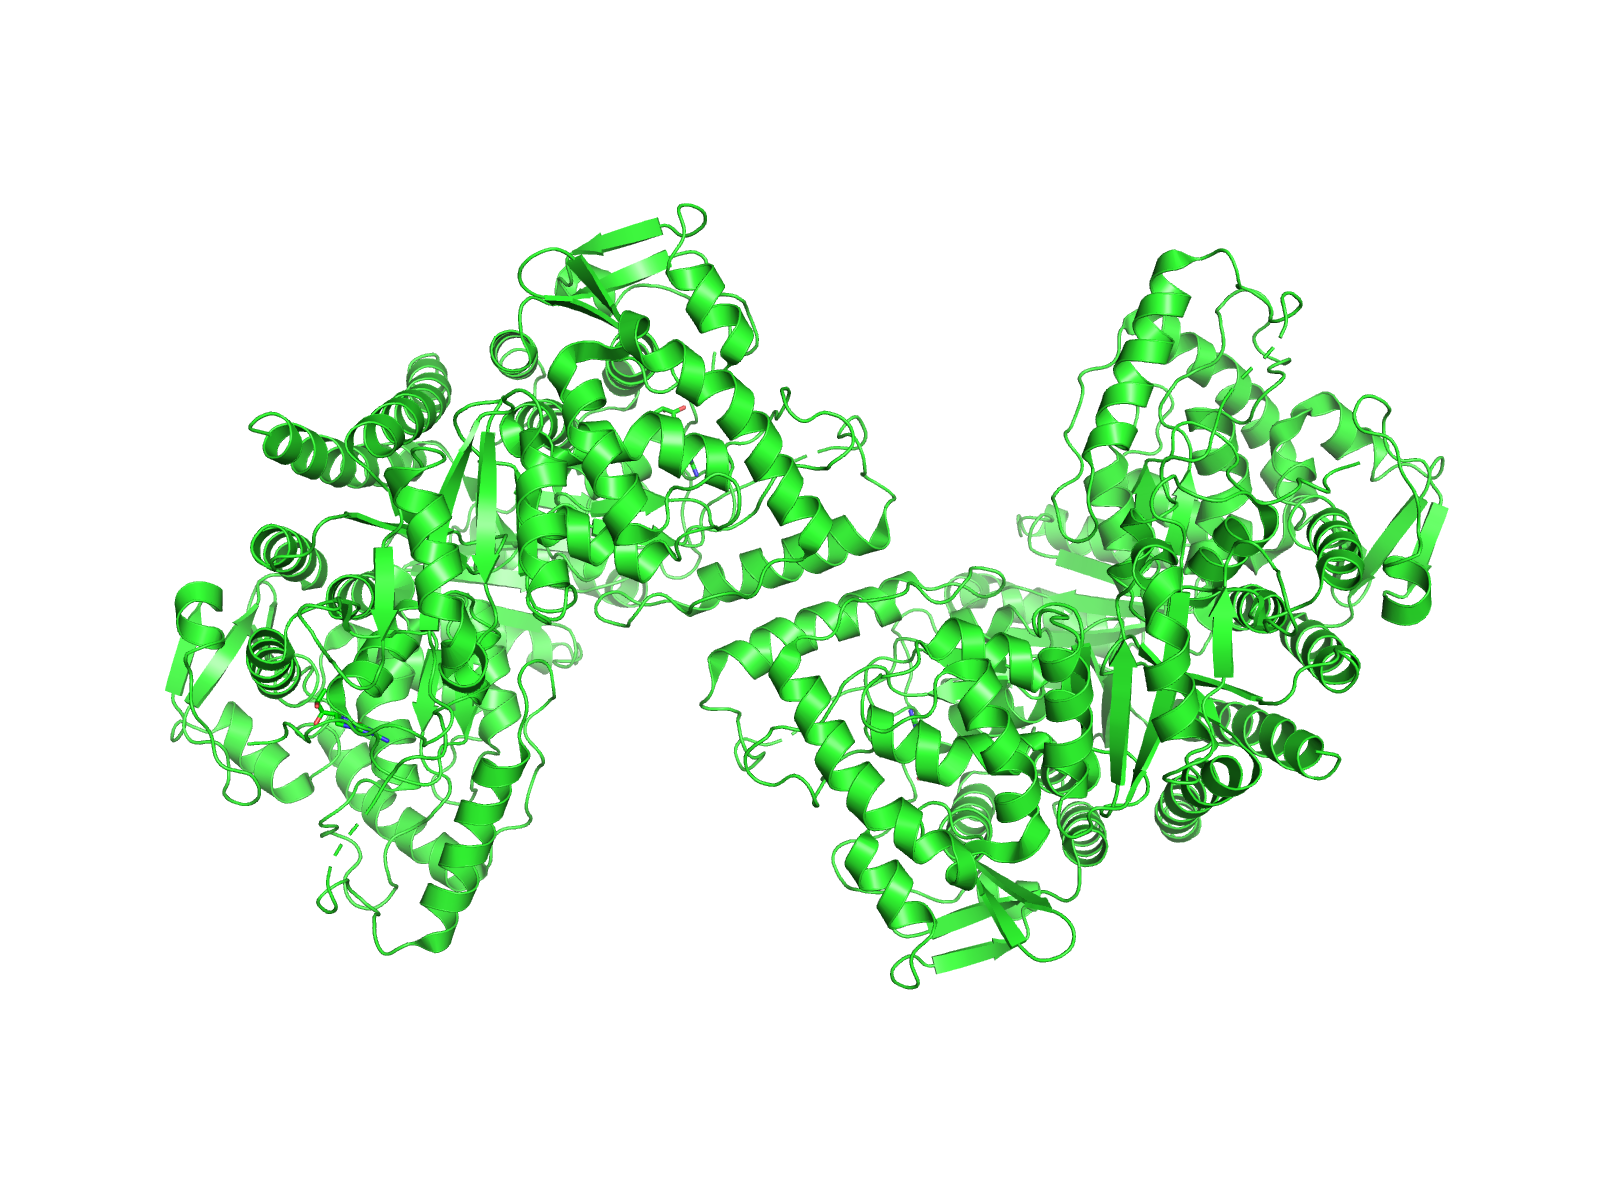

In [17]:
!pymol -cq database/optional_resources/PyMOL_images/render_6HYC.pml
from IPython.display import Image, display
display(Image("database/optional_resources/PyMOL_images/6HYC_figura.png", width=700))

### Visualización con py3Dmol

In [19]:
import py3Dmol
with open("database/optional_resources/protein/6HYC.cif") as f:
    cif_data = f.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(cif_data, "cif")
view.setStyle({"cartoon": {"colorscheme": "chain"}})          # cadenas en colores distintos
view.addStyle({"resn": "H4B"},                                 # ligando H4B
              {"stick": {"colorscheme": "greenCarbon", "radius": 0.25}})
view.zoomTo({"resn": "H4B"})                                   # centra en el ligando
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# Análisis estructural de PAH - PDB 6HYC
La estructura 6HYC corresponde a la fenilalanina-4-hidroxilasa (PAH) humana (*Homo sapiens*), una proteína de 452 aminoácidos. La estructura fue determinada mediante difracción de rayos X con una resolución de 3.18 Å.

**Cadenas:** presenta cuatro cadenas proteicas (A, B, C y D), que forman un homotetrámero.

**Residuos resueltos:** según el informe de validación wwPDB, se modelaron 423 residuos en las cadenas A, C y D, y 424 en la cadena B. Los residuos restantes no presentan coordenadas atómicas en el modelo experimental.

**Ligandos y cofactores:**

* BH4 (H4B): tetrahidrobiopterina, identificada como ligando en la estructura. Actúa como cofactor y regulador negativo de PAH.

* Fe²⁺: cofactor metálico fisiológico de PAH, aunque no está identificado como ligando modelado en 6HYC.

* Agua: también se encuentran moléculas de agua modeladas.

**Dominios de PAH (UniProt P00439 y literatura científica):**

Dominio regulador: residuos 1–117. Incluye la región autorreguladora (1–32) y el subdominio ACT (aproximadamente 33–110).

Dominio catalítico: residuos 118–410. Contiene el sitio activo y participa en la unión del sustrato, hierro y BH4.

Dominio de tetramerización: residuos 411–452. Participa en la asociación de las subunidades para formar el tetrámero.

Fuentes: RCSB Protein Data Bank (6HYC), wwPDB Validation Report, UniProt (P00439) y Flydal et al. (2019), DOI: 10.1073/pnas.1902639116.

In [20]:
%%writefile database/optional_resources/PyMOL_images//dominios_6HYC.pml
load database/optional_resources/protein/6HYC.cif
hide everything
show cartoon
bg_color white
color marine, resi 22-117          # regulatorio (resuelto parcialmente)
color forest, resi 118-410         # catalítico
color salmon, resi 411-450         # tetramerización
show sticks, resn H4B
color yellow, resn H4B and elem C
orient
png database/optional_resources/PyMOL_images/6HYC_dominios.png, dpi=300
quit

Writing database/optional_resources/PyMOL_images//dominios_6HYC.pml


PyMOL>load database/optional_resources/protein/6HYC.cif
TITLE     The structure of full-length human phenylalanine hydroxylase in complex with the cofactor and negative regulator tetrahydrobiopterin
 ExecutiveLoad-Detail: Detected mmCIF
 CmdLoad: "database/optional_resources/protein/6HYC.cif" loaded as "6HYC".
PyMOL>hide everything
PyMOL>show cartoon
PyMOL>bg_color white
PyMOL>color marine, resi 22-117          # regulatorio (resuelto parcialmente)
 Executive: Colored 3111 atoms.
PyMOL>color forest, resi 118-410         # catalítico
 Executive: Colored 9459 atoms.
PyMOL>color salmon, resi 411-450         # tetramerización
 Executive: Colored 1268 atoms.
PyMOL>show sticks, resn H4B
PyMOL>color yellow, resn H4B and elem C
 Executive: Colored 27 atoms.
PyMOL>orient
PyMOL>png database/optional_resources/PyMOL_images/6HYC_dominios.png, dpi=300
 Ray: render time: 3.00 sec. = 1199.6 frames/hour (3.00 sec. accum.).
 ScenePNG: wrote 640x480 pixel image to file "database/optional_resources/PyMOL

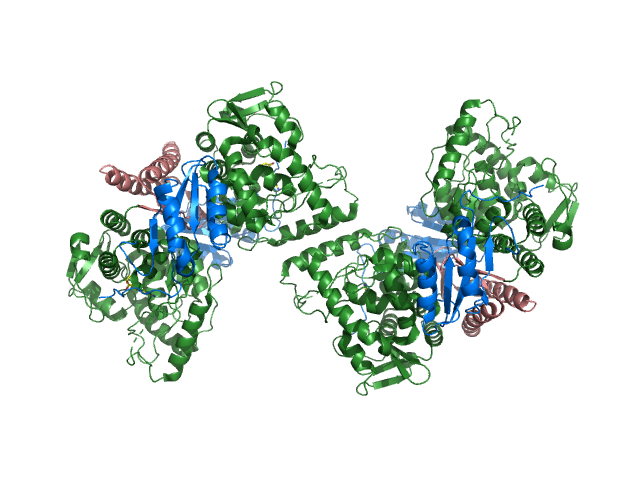

In [ ]:
!pymol -cq database/optional_resources/PyMOL_images/dominios_6HYC.pml
# Visualización con cadenas y ligando resaltado
display(Image("database/optional_resources/PyMOL_images/6HYC_dominios.png", width=700))

## 3. Modelo WT y alineamiento con 6HYC


## 4. Modelos de los mutantes candidatos y su confianza


## 5. Comparación WT vs mutante: RMSD, entorno y contactos


## 6. Figuras y `resultados/estructura_resumen.tsv`


## Cierre de la sección

- **Observamos:**
- **Inferimos que:**
- **La evidencia aporta:**
- **Concluimos:**
- **Falta evidencia:**
